Processing dbpedia100k - star...
Selecting best epoch based on Loss
Using best epoch: 33
Selecting best epoch based on Loss
Using best epoch: 91


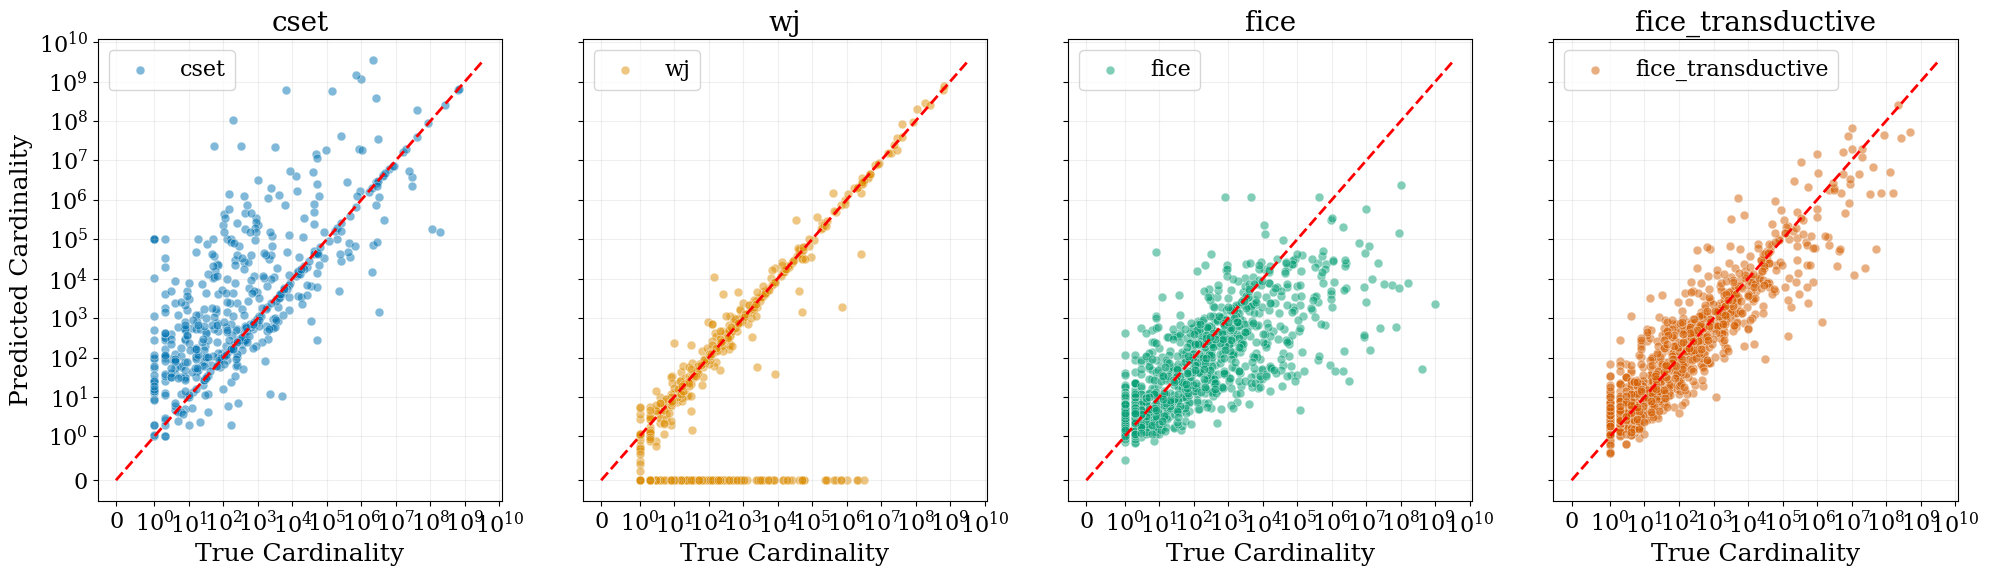

  -> Saved plot to plots_output/scatterplot_cardinality_dbpedia100k_star.pdf
Processing dbpedia100k - path...
Selecting best epoch based on Loss
Using best epoch: 5
Selecting best epoch based on Loss
Using best epoch: 52


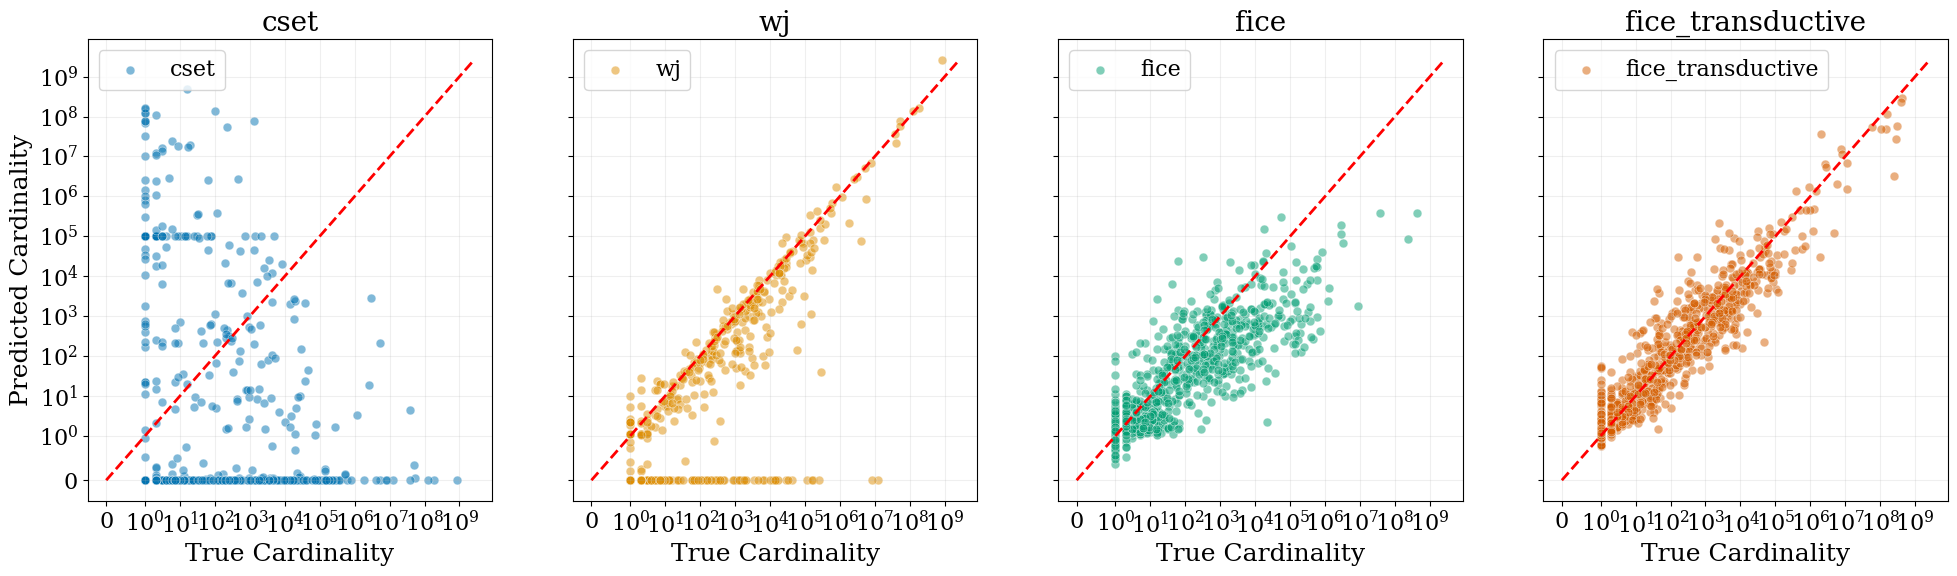

  -> Saved plot to plots_output/scatterplot_cardinality_dbpedia100k_path.pdf
Processing fb237_v4 - star...
Selecting best epoch based on Loss
Using best epoch: 23
Selecting best epoch based on Loss
Using best epoch: 100


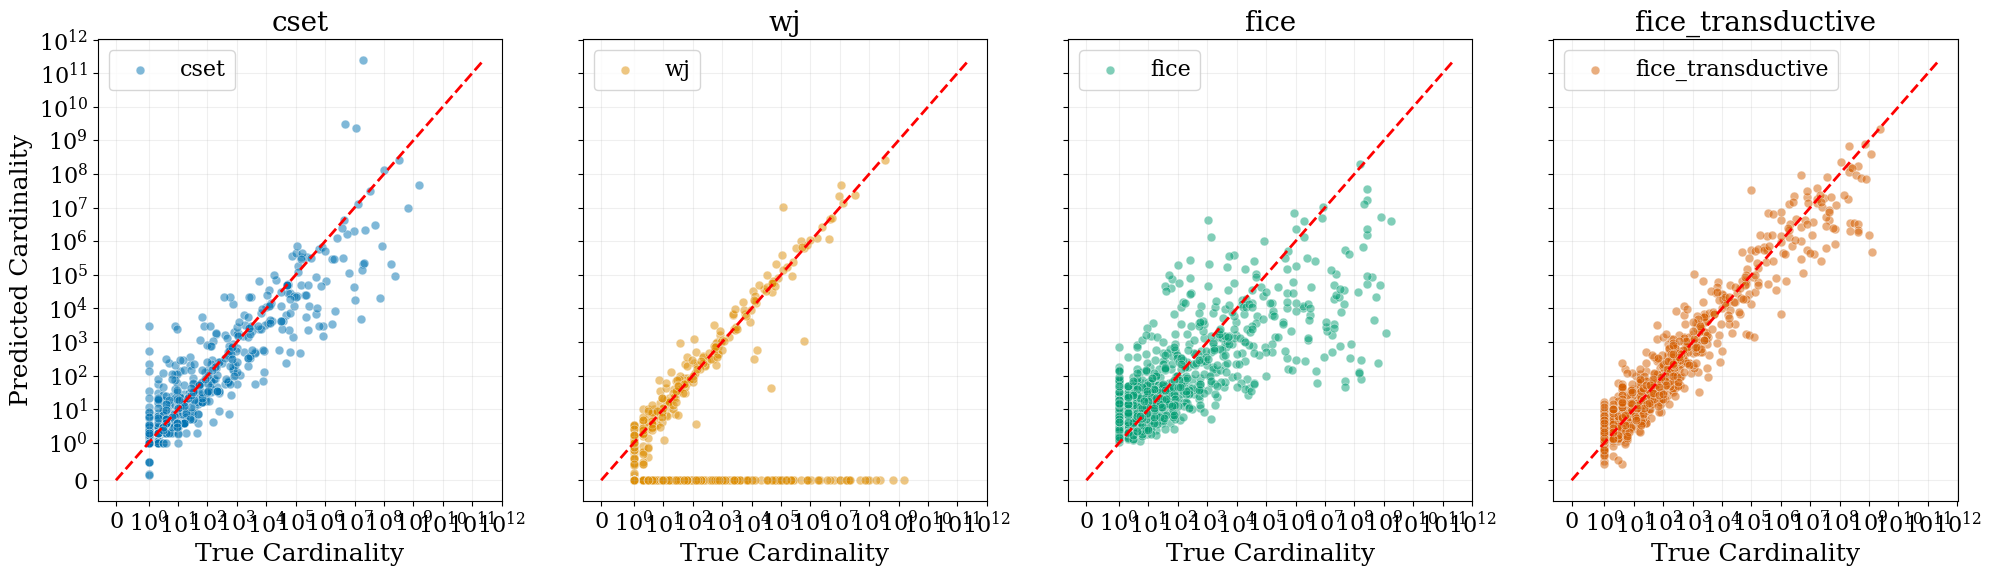

  -> Saved plot to plots_output/scatterplot_cardinality_fb237_v4_star.pdf
Processing fb237_v4 - path...
Selecting best epoch based on Loss
Using best epoch: 64
Selecting best epoch based on Loss
Using best epoch: 98


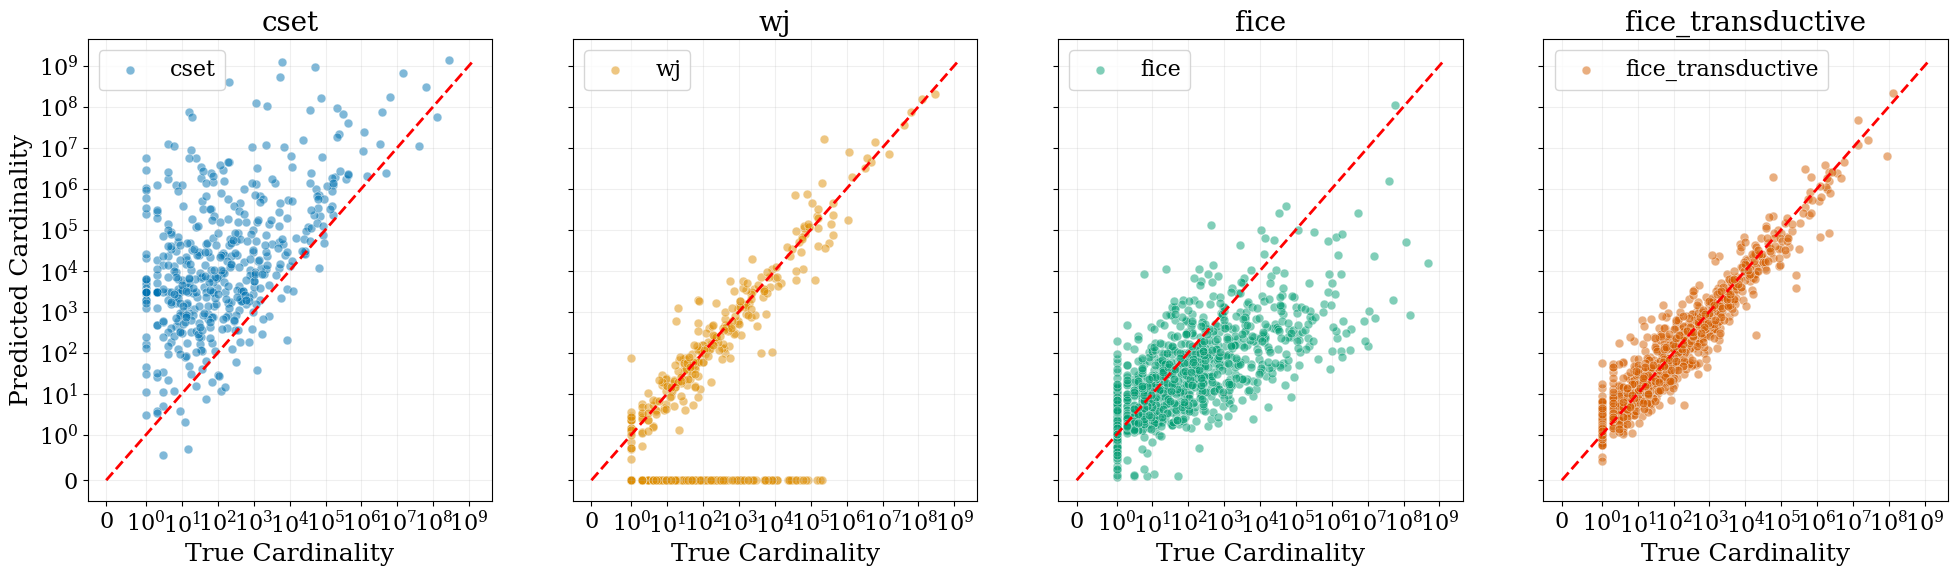

  -> Saved plot to plots_output/scatterplot_cardinality_fb237_v4_path.pdf
Processing lubm - star...
Selecting best epoch based on Loss
Using best epoch: 91
Selecting best epoch based on Loss
Using best epoch: 83


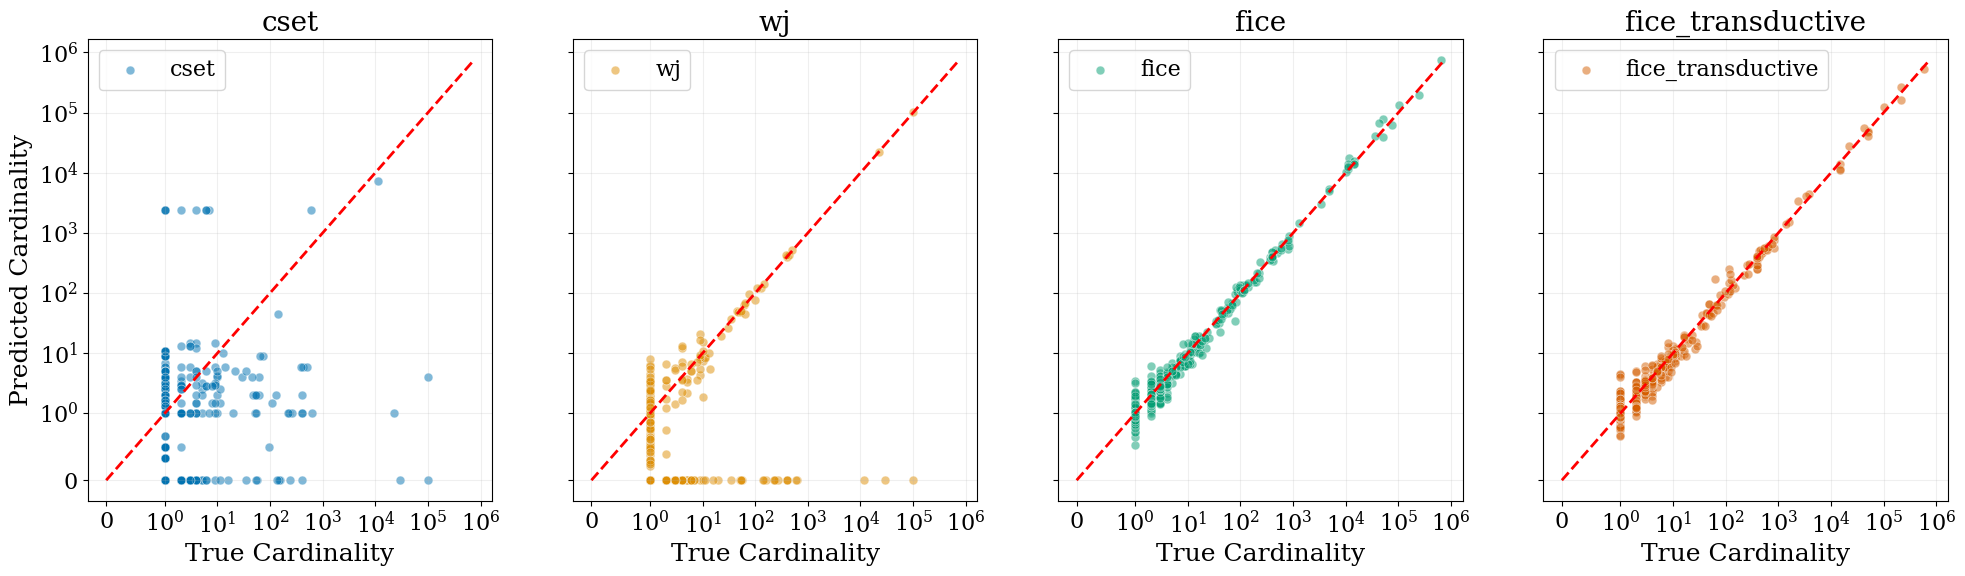

  -> Saved plot to plots_output/scatterplot_cardinality_lubm_star.pdf
Processing lubm - path...
Selecting best epoch based on Loss
Using best epoch: 61
Selecting best epoch based on Loss
Using best epoch: 24


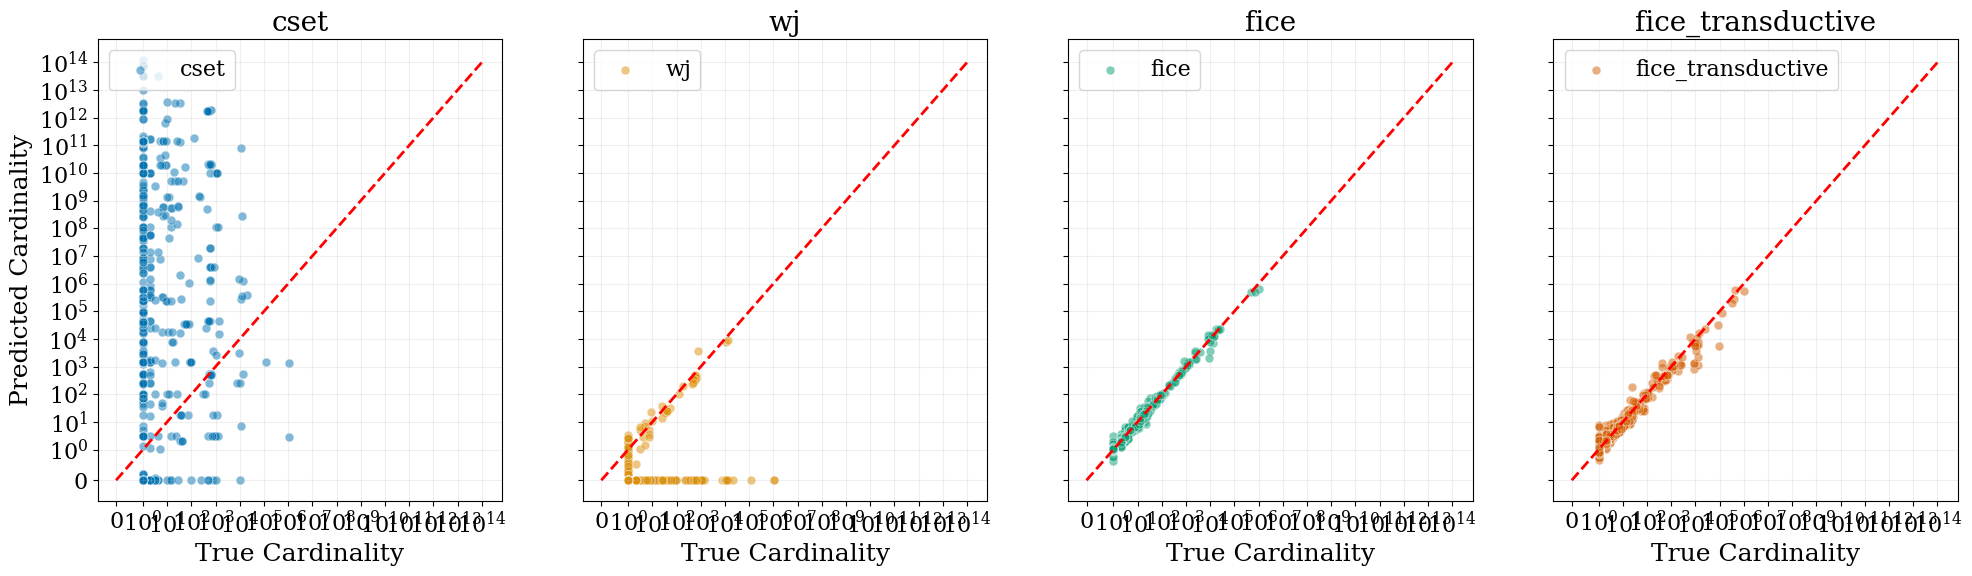

  -> Saved plot to plots_output/scatterplot_cardinality_lubm_path.pdf
Processing swdf - star...
Selecting best epoch based on Loss
Using best epoch: 40
Selecting best epoch based on Loss
Using best epoch: 78


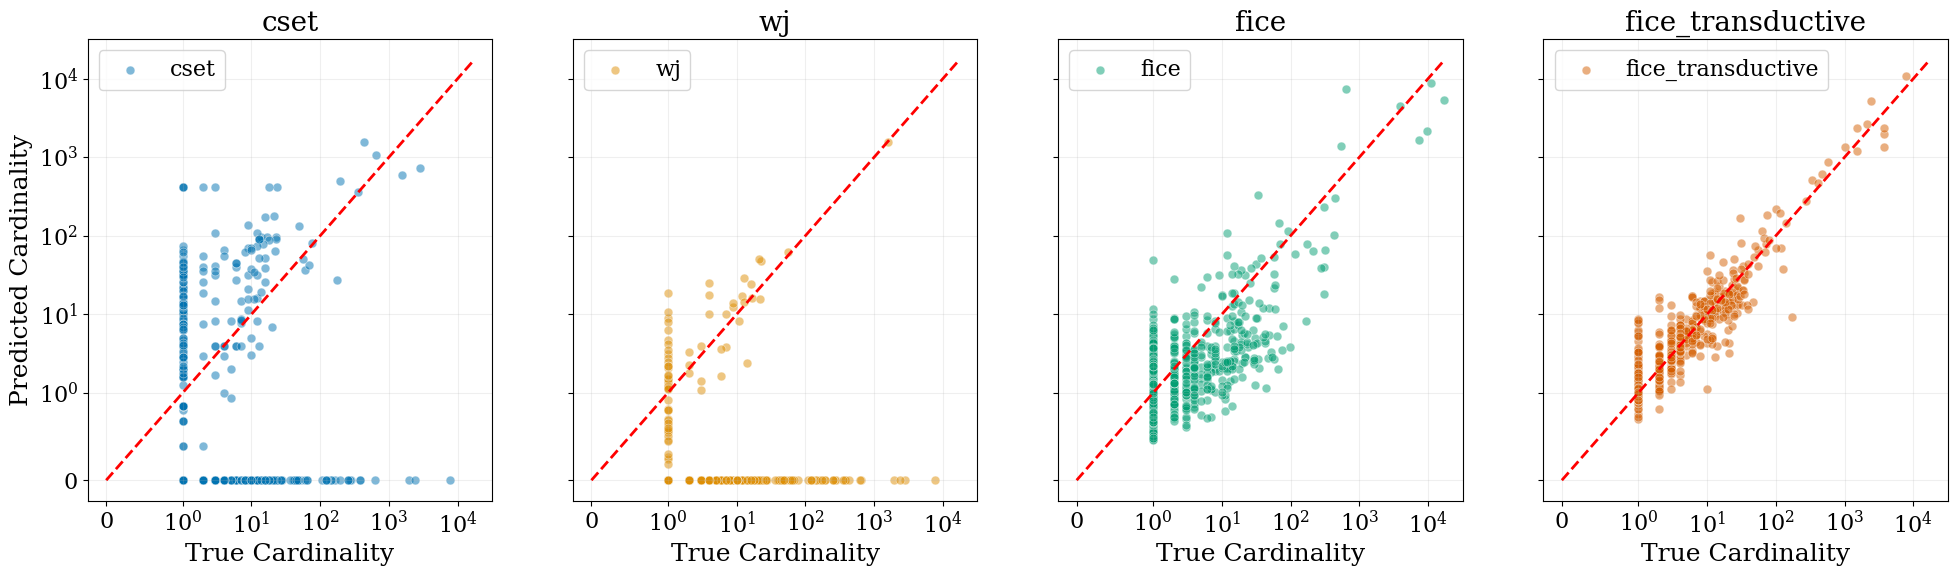

  -> Saved plot to plots_output/scatterplot_cardinality_swdf_star.pdf
Processing swdf - path...
Selecting best epoch based on Loss
Using best epoch: 6
Selecting best epoch based on Loss
Using best epoch: 69


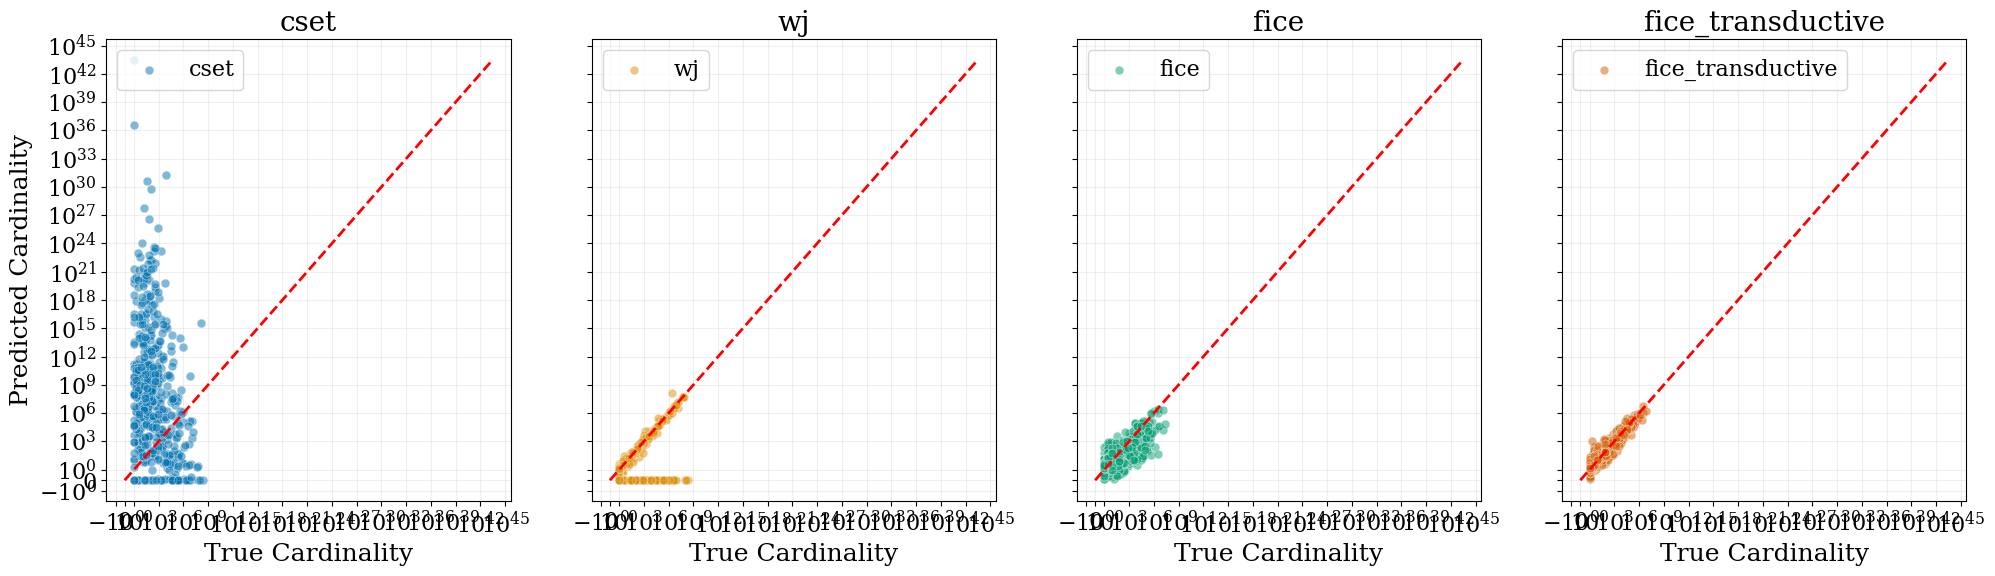

  -> Saved plot to plots_output/scatterplot_cardinality_swdf_path.pdf
Processing wikidata - star...
Selecting best epoch based on Loss
Using best epoch: 7
Selecting best epoch based on Loss
Using best epoch: 7


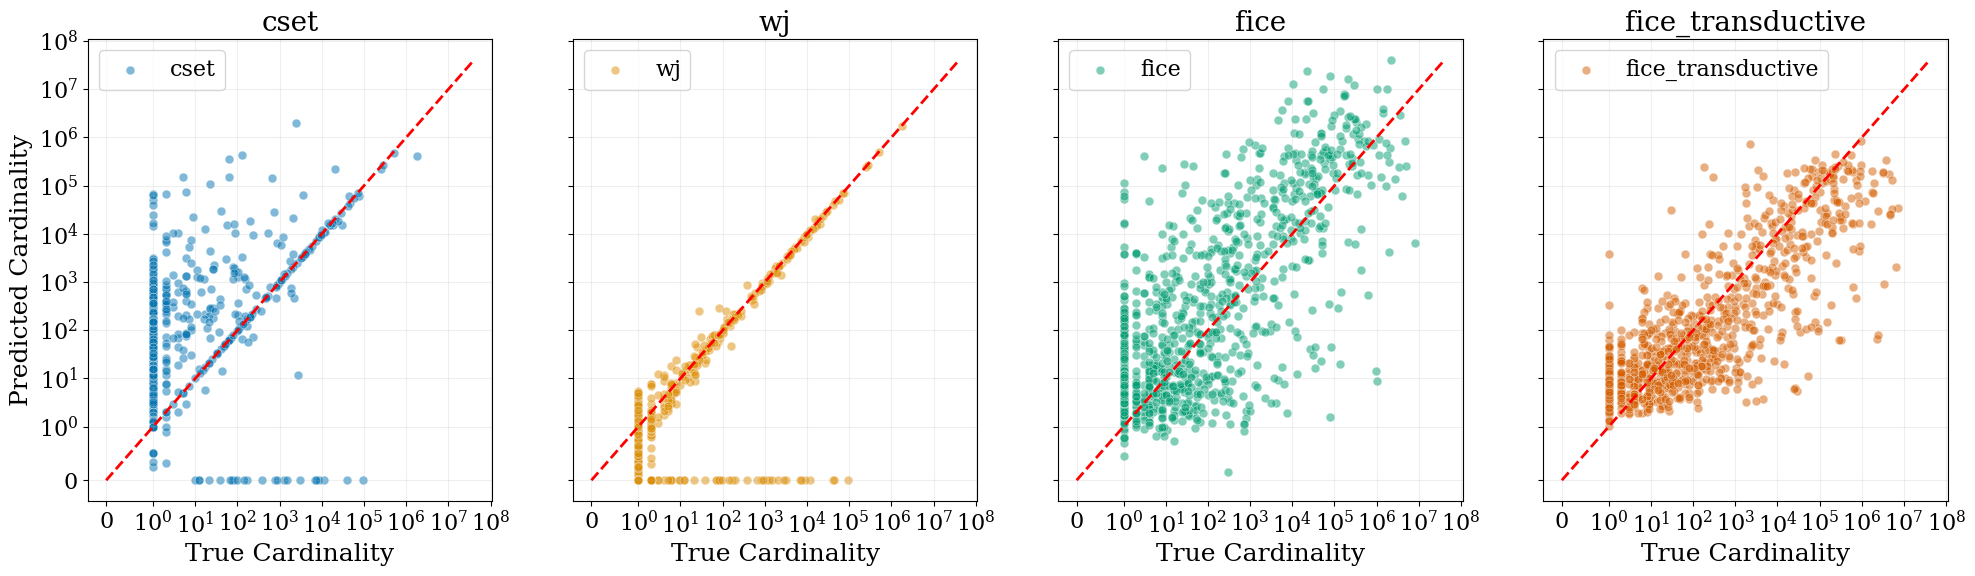

  -> Saved plot to plots_output/scatterplot_cardinality_wikidata_star.pdf
Processing wikidata - path...
Selecting best epoch based on Loss
Using best epoch: 34
Selecting best epoch based on Loss
Using best epoch: 75


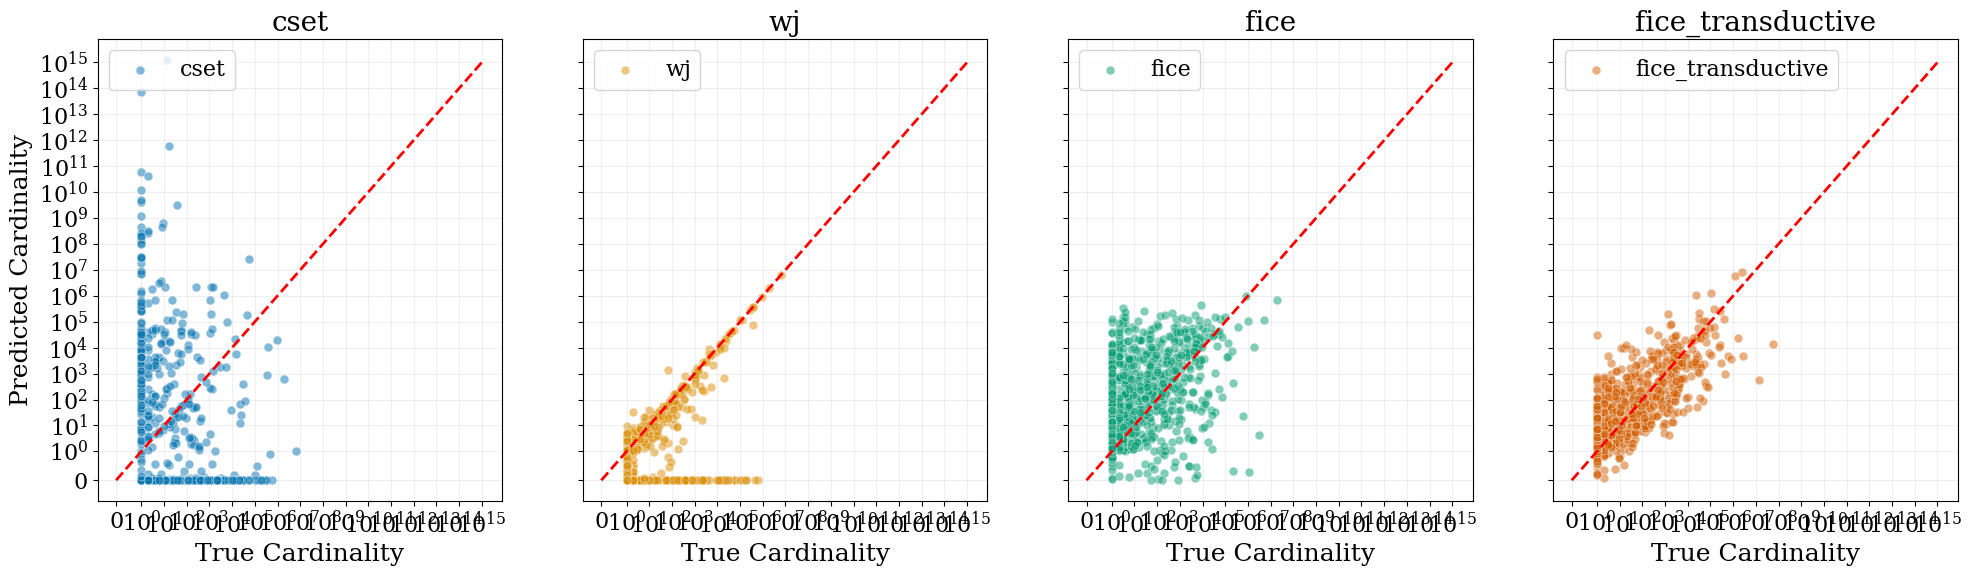

  -> Saved plot to plots_output/scatterplot_cardinality_wikidata_path.pdf
Processing wn18rr_v4 - star...
Selecting best epoch based on Loss
Using best epoch: 33
Selecting best epoch based on Loss
Using best epoch: 75


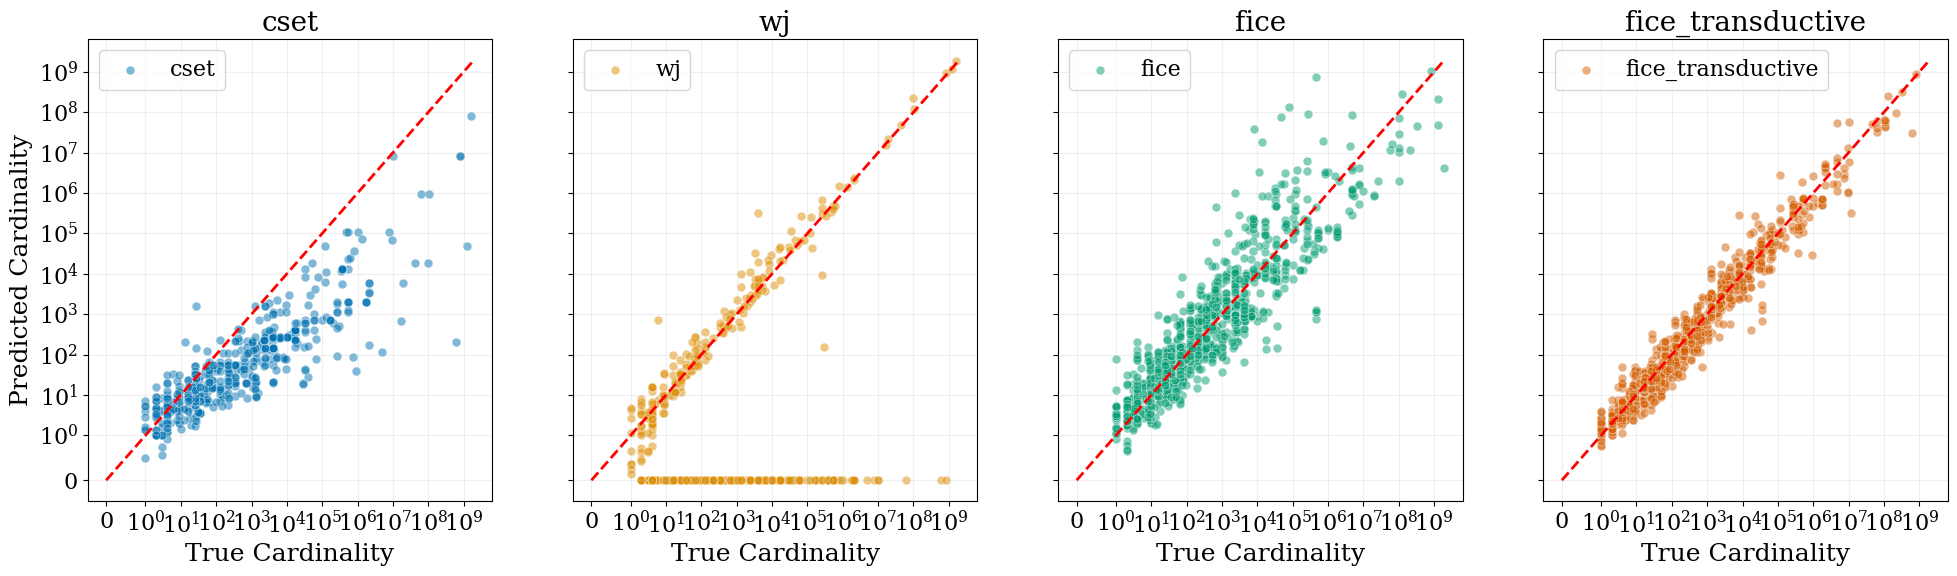

  -> Saved plot to plots_output/scatterplot_cardinality_wn18rr_v4_star.pdf
Processing wn18rr_v4 - path...
Selecting best epoch based on Loss
Using best epoch: 49
Selecting best epoch based on Loss
Using best epoch: 67


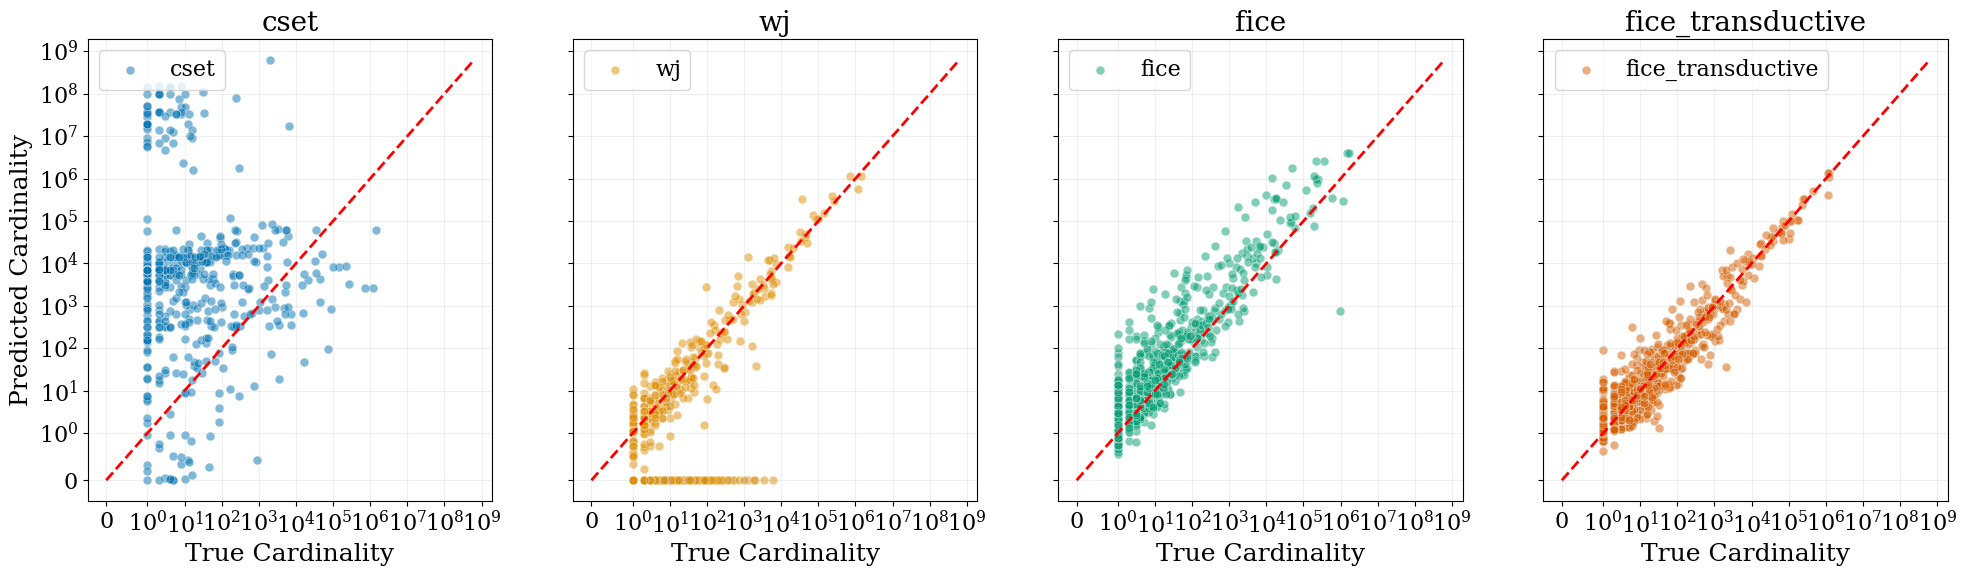

  -> Saved plot to plots_output/scatterplot_cardinality_wn18rr_v4_path.pdf


In [1]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
import pandas as pd
from pathlib import Path
import helper
import importlib

importlib.reload(helper)

FICE_PATH = Path("./fice_runs")
FICE_T_PATH = Path("./fice_runs/transductive")
GCARE_PATH = Path("./gcare_runs")

GRAPHS = [
    'dbpedia100k',
    'fb237_v4',
    'lubm',
    'swdf',
    'wikidata',
    'wn18rr_v4',
]

# Config Mapping: Graph Name -> (GCARE Folder Prefix, FICE Folder Name, FICE Dataset Name in CSV)
CONFIG_MAP = {
    'dbpedia100k': ('dbpedia100k', 'dbpedia100k', 'dbpedia100k'),
    'fb237_v4': ('fb237_v4_ind', 'fb237', 'fb237_v4_ind'),
    'lubm': ('lubm', 'lubm', 'lubm'),
    'swdf': ('swdf', 'swdf', 'swdf'),
    'wikidata': ('wikidata', 'wikidata', 'wikidata'),
    'wn18rr_v4': ('wn18rr_v4_ind', 'wn18rr', 'wn18rr_v4_ind'),
}

OUTPUT_DIR = Path("plots_output")
OUTPUT_DIR.mkdir(exist_ok=True)

for graph in GRAPHS:
    if graph not in CONFIG_MAP:
        print(f"Skipping {graph}: No config found.")
        continue
        
    gcare_prefix, fice_folder, fice_ds_name = CONFIG_MAP[graph]
    
    for q_type in ['star', 'path']:
        print(f"Processing {graph} - {q_type}...")
        
        # 1. Load GCARE Data
        # Path structure: {prefix}_{type}/{type}/{prefix}_{type}
        gcare_subpath = f"{gcare_prefix}_{q_type}/{q_type}/{gcare_prefix}_{q_type}"
        gcare_full_path = GCARE_PATH / gcare_subpath
        
        if not gcare_full_path.exists():
            print(f"  [Warning] GCARE path not found: {gcare_full_path}")
            continue
            
        try:
            gcare_df = helper.process_gcare(gcare_full_path)
        except Exception as e:
            print(f"  [Error] Failed to process GCARE: {e}")
            continue
            
        # 2. Load FICE Data
        fice_full_path = FICE_PATH / fice_folder
        if not fice_full_path.exists():
            print(f"  [Warning] FICE path not found: {fice_full_path}")
            continue
            
        try:
            fice_df = helper.process_fice(fice_full_path, fice_ds_name, q_type)
        except Exception as e:
            print(f"  [Error] Failed to process FICE: {e}")
            continue

        # 3. Load FICE Transductive Data
        fice_t = FICE_T_PATH
        if not fice_t.exists():
            print(f"  [Warning] FICE path not found: {fice_t}")
            continue
            
        try:
            fice_t_df = helper.process_fice_transductive(fice_t, fice_ds_name, q_type, epoch=None)
        except Exception as e:
            print(f"  [Error] Failed to process FICE: {e}")
            continue
            
        # 4. Combine and Plot
        combined_df = pd.concat([gcare_df, fice_df, fice_t_df], ignore_index=True)
        
        try:
            helper.plot_cardinality_scatterplot(combined_df, str(OUTPUT_DIR), display=True, separate_plots=True, max_points=1000)
            
            # Rename output file to be unique
            src_file = OUTPUT_DIR / 'scatterplot_cardinality.pdf'
            dst_file = OUTPUT_DIR / f'scatterplot_cardinality_{graph}_{q_type}.pdf'
            if src_file.exists():
                src_file.rename(dst_file)
                print(f"  -> Saved plot to {dst_file}")
        except Exception as e:
            print(f"  [Error] Failed to plot: {e}")